##### Feladat

Határozzuk meg az igénybevételi függvényeket és rajzoljuk fel az igénybevételi ábrákat!

<img src="img/01.jpg" alt="Feladat" width=420px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
L = 1 # m
a = sp.Rational(4, 10) # m (sp.Rational: törtként kezeli, nem float-ként)

F = 4 # kN

# Rúdirányú koordináta
x = sp.symbols('x')

##### Előjelkonvenció

Az igénybevételek előjelét az alábbi előjelkonvenció szerint határozzuk meg (lásd a 8.1 feladatot):

<img src="img/02.jpg" alt="Feladat" width=300px>

##### Szabadtest ábra

<img src="img/03.jpg" alt="Feladat" width=420px>

##### A reakciók

In [3]:
A_x, A_y, B_y = sp.symbols('A_x, A_y, B_y')

##### Egyensúlyi egyenletek

In [4]:
# x irányú erő egyensúly
eq1 = A_x
display(Math(rf'\sum F_x = 0 \quad \longrightarrow \quad {latex(eq1)} = 0 \qquad (1)'))

# y irányú erő egyensúly
eq2 = A_y - F + B_y
display(Math(rf'\sum F_y = 0 \quad \longrightarrow \quad {latex(eq2)} = 0 \qquad (2)'))

# z irányú nyomatéki egyensúly az A pontra
eq3 = -F*a + B_y*L
display(Math(rf'\sum M_A = 0 \quad \longrightarrow \quad {latex(eq3)} = 0 \qquad (3)'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Egyensúlyi egyenletek megoldása

In [5]:
sol = sp.solve([eq1, eq2, eq3], [A_x, A_y, B_y])

A_xsol = sol[A_x]
display(Math(rf'A_x = {latex(round(A_xsol, 2))} ~ \mathrm{{kN}}'))

A_ysol = sol[A_y]
display(Math(rf'A_y = {latex(round(A_ysol, 2))} ~ \mathrm{{kN}}'))

B_ysol = sol[B_y]
display(Math(rf'B_y = {latex(round(B_ysol, 2))} ~ \mathrm{{kN}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Szakaszok

* Megjelenik az $F$ erő a tartó közepén → 2 részre kell bontani az igénybevételi függvényeket!

* 1. szakasz: $x \in [0, a]$

* 2. szakasz: $x \in [a, L]$

<img src="img/04.jpg" alt="Feladat" width=420px>

##### Az igénybevételi függvények

Mindkét szakaszon balról redukálunk, mivel a reakciók már ismertek.

##### 1. szakasz: $x \in [0, a]$

A $K$ keresztmetszettől balra csak az $A_x$ és $A_y$ reakcióerők hatnak.

In [6]:
# Normálerő: az A_x erő jobbra mutat, ami balról nézve negatív
N_1 = -A_xsol
display(Math(rf'N_1(x) = {latex(round(N_1, 2))}'))

# Nyíróerő: az A_y erő felfelé mutat, ami balról nézve pozitív
V_1 = A_ysol
display(Math(rf'V_1(x) = A_y = {latex(round(V_1, 2))} ~ \mathrm{{kN}}'))

# Hajlítónyomaték: az A_y erő nyomatéka a K pontra az óramutató járásával megegyező, ami balról nézve negatív
M_h1 = -A_ysol*x
display(Math(rf'M_{{h1}}(x) = -A_y \cdot x = {latex(M_h1.evalf(3))} ~ \mathrm{{kNm}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Csavarónyomaték: nincs rúdirányú nyomaték
M_t1 = sp.Integer(0)
display(Math(rf'M_{{t1}}(x) = {latex(M_t1)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### 2. szakasz: $x \in [a, L]$

A $K$ keresztmetszettől balra az $A_x$ és $A_y$ reakcióerők és az $F$ erő hatnak.

In [7]:
# Normálerő: az A_x erő jobbra mutat, ami balról nézve negatív
N_2 = -A_xsol
display(Math(rf'N_2(x) = {latex(round(N_2, 2))}'))

# Nyíróerő: az A_y erő felfelé mutat (balról nézve pozitív), az F erő lefelé mutat (balról nézve negatív)
V_2 = A_ysol - F
display(Math(rf'V_2(x) = A_y - F = {latex(round(V_2, 2))} ~ \mathrm{{kN}}'))

# Hajlítónyomaték: az A_y nyomatéka a K pontra az óramutató járásával megegyező (balról nézve negatív),
# az F nyomatéka az óramutató járásával ellentétes (balról nézve pozitív)
M_h2 = -A_ysol*x + F*(x - a)
display(Math(rf'M_{{h2}}(x) = -A_y \cdot x + F \cdot (x - a) = {latex(M_h2.evalf(3))} ~ \mathrm{{kNm}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Csavarónyomaték: nincs rúdirányú nyomaték
M_t2 = sp.Integer(0)
display(Math(rf'M_{{t2}}(x) = {latex(M_t2)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Ellenőrzés

* A hajlítónyomaték az $x = a$ szakaszhatáron folytonos, a $B$ támasznál ($x = L$) pedig nulla.

* Derivált kapcsolat: $M_h'(x) = -V(x)$ mindkét szakaszon.

In [8]:
# A hajlítónyomaték a szakaszhatáron mindkét szakasz függvényéből
display(Math(rf'M_{{h1}}(x=a) = {latex(round(M_h1.subs(x, a), 2))} ~ \mathrm{{kNm}} \qquad M_{{h2}}(x=a) = {latex(round(M_h2.subs(x, a), 2))} ~ \mathrm{{kNm}}'))

# A hajlítónyomaték a B támasznál
display(Math(rf'M_{{h2}}(x=L) = {latex(round(M_h2.subs(x, L), 2))} ~ \mathrm{{kNm}}'))

# Derivált kapcsolatok
display(Math(rf"M_{{h1}}'(x) = {latex(round(sp.diff(M_h1, x), 2))} \qquad -V_1(x) = {latex(round(-V_1, 2))}"))
display(Math(rf"M_{{h2}}'(x) = {latex(round(sp.diff(M_h2, x), 2))} \qquad -V_2(x) = {latex(round(-V_2, 2))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Látható, hogy az összefüggések teljesülnek.

##### Ábrázolás

In [9]:
def igenybeveteli_abra(ax, f, x_0, x_1, felirat, szin='red'):
    # A függvény kiértékelése numerikusan az [x_0, x_1] tartományon
    x_vals = np.linspace(x_0, x_1, 201)
    f_vals = sp.lambdify(x, f, 'numpy')(x_vals) * np.ones_like(x_vals) # Konstans függvény esetén is tömböt kapunk
    # A függvény görbéje (zorder: az x tengely fölé rajzoljuk)
    ax.plot(x_vals, f_vals, color=szin, lw=1.5, zorder=3)
    # Satírozás a görbe és az x tengely között (mint a kézi rajzokon)
    ax.vlines(x_vals[::10], 0, f_vals[::10], color=szin, lw=0.8)
    # Lezárás a tartomány két végén
    ax.vlines([x_0, x_1], 0, [f_vals[0], f_vals[-1]], color=szin, lw=1.5, zorder=3)
    # Az x tengely
    ax.axhline(0, color='black', lw=1)
    ax.set_ylabel(felirat)
    ax.grid(True, alpha=0.5)

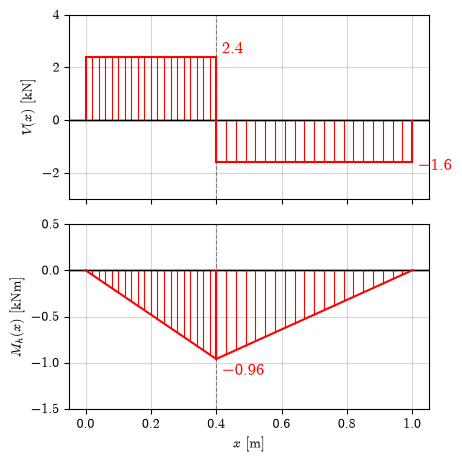

In [10]:
# A szakaszhatár float-ként az ábrázoláshoz
a_f = float(a)

fig, axs = plt.subplots(2, 1, figsize=(12/2.54, 12/2.54), sharex=True)

# V(x) a két szakaszon
igenybeveteli_abra(axs[0], V_1, 0, a_f, r'$V(x) ~ [\mathrm{kN}]$')
igenybeveteli_abra(axs[0], V_2, a_f, L, r'$V(x) ~ [\mathrm{kN}]$')
axs[0].annotate(rf'${latex(round(V_1, 2))}$', xy=(a_f, float(V_1)), xytext=(4, 2), textcoords='offset points', color='red', fontsize=12)
axs[0].annotate(rf'${latex(round(V_2, 2))}$', xy=(L, float(V_2)), xytext=(4, -6), textcoords='offset points', color='red', fontsize=12)
axs[0].set_ylim(-3, 4)

# M_h(x) a két szakaszon
igenybeveteli_abra(axs[1], M_h1, 0, a_f, r'$M_h(x) ~ [\mathrm{kNm}]$')
igenybeveteli_abra(axs[1], M_h2, a_f, L, r'$M_h(x) ~ [\mathrm{kNm}]$')
axs[1].annotate(rf'${latex(round(M_h1.subs(x, a), 2))}$', xy=(a_f, float(M_h1.subs(x, a))), xytext=(4, -12), textcoords='offset points', color='red', fontsize=12)
axs[1].set_ylim(-1.5, 0.5)

# Szakaszhatár
for ax in axs:
    ax.axvline(a_f, color='gray', ls='--', lw=0.8)

axs[1].set_xlabel(r'$x ~ [\mathrm{m}]$')
plt.tight_layout()
plt.savefig('igenybeveteli_fuggvenyek.pdf') # Az ábra mentése PDF dokumentumba
plt.show()